# Visium dataset gallery benchmark
This notebook demonstrates the speed of rendering several Visium whole-slide image ROIs in the dataset gallery with a standardized marker scaling. This rendering mimics the dataset gallery rendering seen here: https://rakaia.io/docs/roi#region-thumbnail-gallery
\
This dataset is available at: https://cellxgene.cziscience.com/collections/4195ab4c-20bd-4cd3-8b3d-65601277e731 and consists of 10 Visium spatial transcriptomics samples of human breast. 

In [49]:
import warnings
warnings.filterwarnings('ignore')

In [50]:
import time
import math
from pathlib import Path
import json
import glob
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from rakaia.parsers.roi import RegionThumbnail

In [51]:
file_uploads = {'uploads': list(glob.glob("/home/admin/rakaia/publication/navin_breast/expr/*.h5ad"))}

with open("./visium_blend_gallery.json", "r", encoding="utf-8") as file:
    blend_params = json.load(file)

roi_options = [f"{roi_id}---slideNA---acq" for roi_id in ([str(Path(file_path).stem) for file_path in file_uploads['uploads']])]
start = time.time()
images_for_gallery = RegionThumbnail(file_uploads, blend_params['channels'], ['MMP7', 'KRT17', 'MUCL1'], 10, dataset_options=roi_options, 
                    delimiter="---", use_greyscale=False, single_channel_view=False, spatial_radius=55, use_scaling=True, enable_masks=False).get_image_dict()
end = time.time()
print(f"Rendering time for gallery images: {end - start:.4f}s")

Rendering time for gallery images: 26.1661s


It takes approximately **2.5-3 seconds** to render each of the Visium whole slide images with the three-marker blend. Each image is approximately 6500x6500 pixels.

A recreation of Rakaia's dataset gallery allows the entire slide collection to be viewed simultaneously with a standarized marker blend consisting of MMP7, KRT17, and MUCL1:

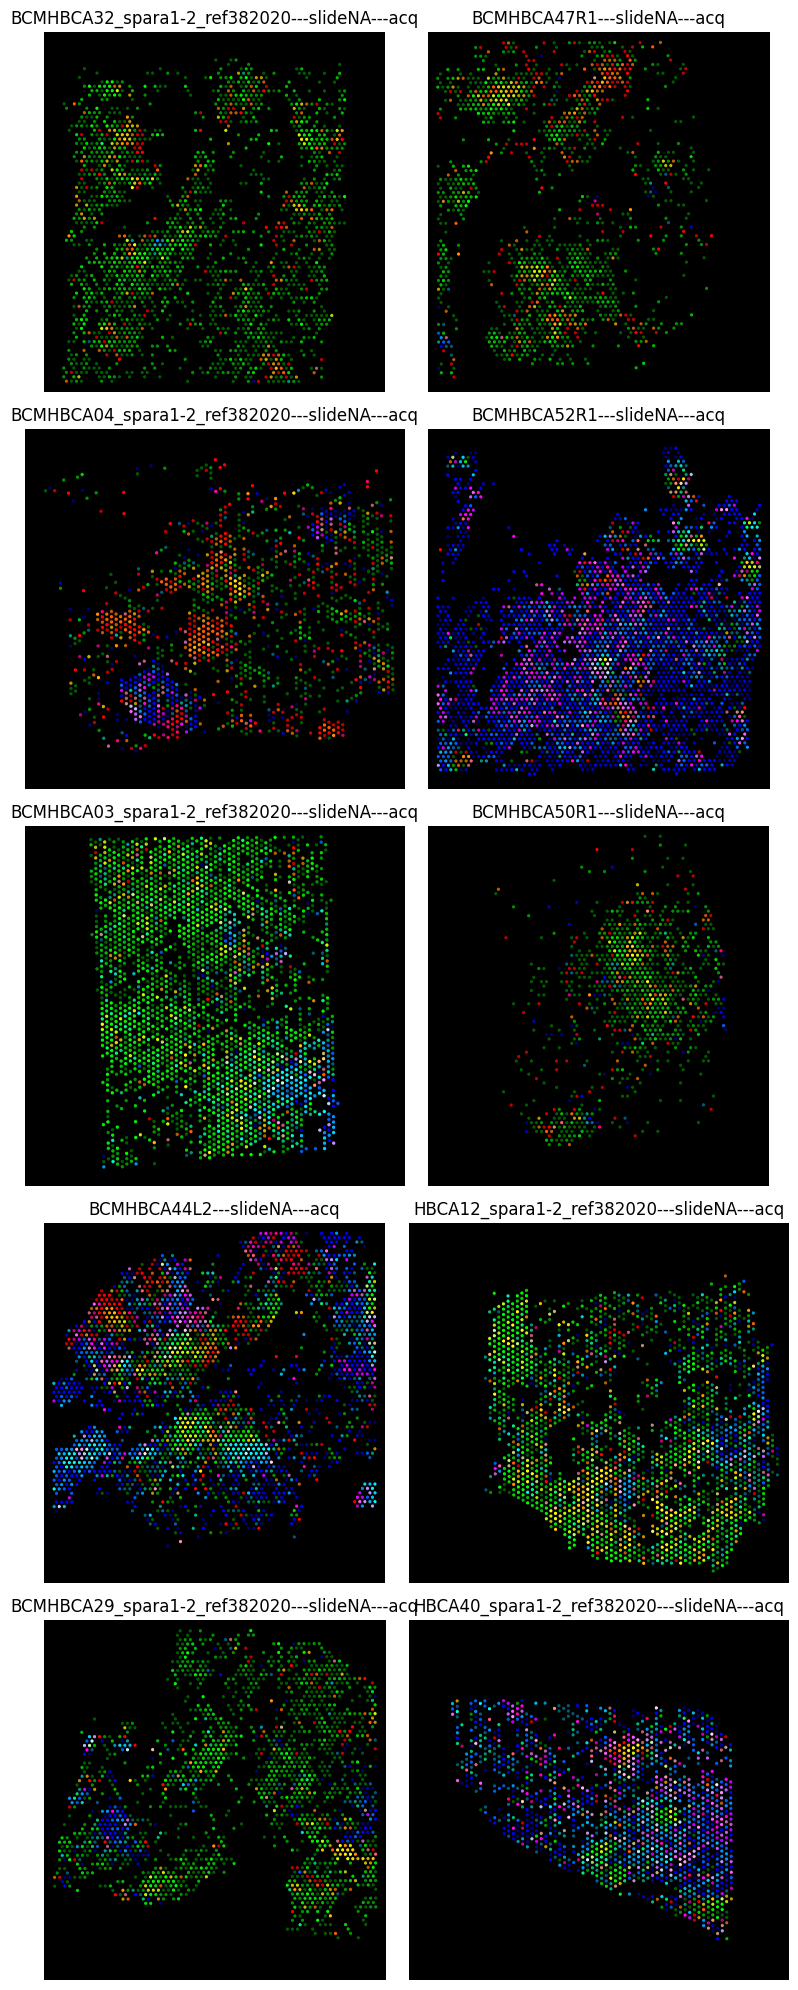

In [48]:
def mock_image_gallery(images, ncols=2):
    n = len(images)
    nrows = math.ceil(n / ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows))
    axes = axes.flatten()

    for ax, (label, img) in zip(axes, images.items()):
        ax.imshow(img)
        ax.set_title(str(label))
        ax.axis("off")

    # Hide unused axes
    for ax in axes[n:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

mock_image_gallery(images_for_gallery)